# Ajuste de hiperparámetros en Machine Learning

**Validación cruzada y búsqueda de hiperparámetros con scikit-learn**

En este cuaderno aprenderemos:

1. Qué son los **hiperparámetros** y por qué hay que ajustarlos.
2. Cómo evaluar un modelo de forma fiable con **validación cruzada**:
   - `cross_val_score`
   - `KFold`
   - `StratifiedKFold`
3. Cómo encadenar preprocesamiento y modelo con **pipelines** (`make_pipeline`).
4. Cómo buscar automáticamente los mejores hiperparámetros:
   - `GridSearchCV`
   - `RandomizedSearchCV`

Usaremos los modelos que ya conocemos: **regresión lineal**, **regresión logística**, **k-NN** y **árboles de decisión**, y conjuntos de datos que vienen incluidos en scikit-learn (no hace falta descargar nada).

## 0. Preparación

Importamos las librerías que usaremos a lo largo del cuaderno.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_breast_cancer, load_diabetes
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     KFold, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

import warnings
warnings.filterwarnings("ignore")

## 1. Parámetros vs. hiperparámetros

- **Parámetros**: valores que el modelo **aprende solo** a partir de los datos durante el entrenamiento (`fit`).
  Ejemplo: los coeficientes de una regresión lineal, o las preguntas (cortes) que hace un árbol de decisión.
- **Hiperparámetros**: valores que **elegimos nosotros antes** de entrenar. Controlan *cómo* aprende el modelo.

| Modelo | Hiperparámetros más habituales | Qué controlan |
|---|---|---|
| `LinearRegression` | `fit_intercept` | Casi no tiene: se usa la validación cruzada sobre todo para **evaluarlo** |
| `LogisticRegression` | `C`, `max_iter` | `C` es la inversa de la regularización: `C` pequeño = modelo más simple |
| `KNeighborsClassifier` | `n_neighbors`, `weights`, `p` | Cuántos vecinos se consultan, si pesan igual o según la distancia, tipo de distancia |
| `DecisionTreeClassifier` | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` | Profundidad y tamaño del árbol (evitar sobreajuste) |

**Idea clave:** no existe un valor de hiperparámetro "correcto" universal. Depende de los datos, así que hay que **probar varios y medir cuál funciona mejor**. Para medirlo bien necesitamos la validación cruzada.

## 2. El problema: una sola división train/test no es fiable

Hasta ahora hemos dividido los datos en entrenamiento y prueba con `train_test_split`. Veamos qué pasa si repetimos esa división con distintas semillas (`random_state`) usando **exactamente el mismo modelo**.

In [2]:
X, y = load_iris(return_X_y=True)

for semilla in range(6):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=semilla)
    modelo = KNeighborsClassifier(n_neighbors=5)
    modelo.fit(X_train, y_train)
    print(f"Semilla {semilla}: accuracy en test = {modelo.score(X_test, y_test):.3f}")

Semilla 0: accuracy en test = 0.967
Semilla 1: accuracy en test = 1.000
Semilla 2: accuracy en test = 1.000
Semilla 3: accuracy en test = 0.967
Semilla 4: accuracy en test = 0.967
Semilla 5: accuracy en test = 0.933


La precisión cambia según **qué datos han caído por azar** en el conjunto de prueba. Si usáramos esta medida para elegir hiperparámetros, podríamos elegir uno que ha tenido "suerte" con la división.

**Solución: validación cruzada (cross-validation).** Dividimos los datos en *k* partes (*folds*), entrenamos *k* veces dejando cada vez una parte distinta para prueba y **promediamos** los resultados.

```
Ronda 1:  [PRUEBA] [entreno] [entreno] [entreno] [entreno]
Ronda 2:  [entreno] [PRUEBA] [entreno] [entreno] [entreno]
Ronda 3:  [entreno] [entreno] [PRUEBA] [entreno] [entreno]
Ronda 4:  [entreno] [entreno] [entreno] [PRUEBA] [entreno]
Ronda 5:  [entreno] [entreno] [entreno] [entreno] [PRUEBA]
                                   → resultado final = media de las 5 rondas
```

## 3. `cross_val_score`: validación cruzada en una línea

`cross_val_score` hace todo el proceso anterior por nosotros y devuelve **una puntuación por cada fold**.

Argumentos principales:
- `estimator`: el modelo (sin entrenar).
- `X`, `y`: los datos.
- `cv`: número de folds (o un objeto `KFold` / `StratifiedKFold`, que veremos después).
- `scoring`: la métrica. Por defecto usa `accuracy` en clasificación y `R²` en regresión.

### Ejemplo 3.1 — Clasificación con k-NN (dataset Iris)

In [ ]:
X, y = load_iris(return_X_y=True)

knn = KNeighborsClassifier(n_neighbors=5)
puntuaciones = cross_val_score(knn, X, y, cv=5, scoring="accuracy") # devuelve un array numpy con una puntuación por fold

print("Accuracy en cada fold:", np.round(puntuaciones, 3)) # redondeo.
print(f"Media: {puntuaciones.mean():.3f}   Desviación típica: {puntuaciones.std():.3f}")

Accuracy en cada fold: [0.967 1.    0.933 0.967 1.   ]
Media: 0.973   Desviación típica: 0.025


- La **media** es nuestra estimación de lo bien que funciona el modelo.
- La **desviación típica** indica lo estable que es: si es grande, el resultado depende mucho de los datos.

### Ejemplo 3.2 — Regresión lineal (dataset Diabetes)

En regresión podemos usar `R²` o el error. scikit-learn siempre **maximiza** las puntuaciones, por eso los errores aparecen con signo negativo (`neg_mean_squared_error`): un valor más cercano a 0 es mejor.

In [4]:
X, y = load_diabetes(return_X_y=True)

reg = LinearRegression()

r2 = cross_val_score(reg, X, y, cv=5, scoring="r2")
mse = cross_val_score(reg, X, y, cv=5, scoring="neg_mean_squared_error")

print("R² por fold:  ", np.round(r2, 3), f"→ media {r2.mean():.3f}")
print("MSE por fold: ", np.round(-mse, 1), f"→ media {-mse.mean():.1f}")

R² por fold:   [0.43  0.523 0.483 0.426 0.55 ] → media 0.482
MSE por fold:  [2779.9 3028.8 3237.7 3008.7 2910.2] → media 2993.1


> Métricas útiles para `scoring`:
> - Clasificación: `"accuracy"`, `"precision"`, `"recall"`, `"f1"`, `"roc_auc"`
> - Regresión: `"r2"`, `"neg_mean_squared_error"`, `"neg_mean_absolute_error"`, `"neg_root_mean_squared_error"`

## 4. `KFold`: controlar cómo se hacen los folds

Cuando escribimos `cv=5`, scikit-learn decide por nosotros cómo dividir. Con `KFold` controlamos la división:

- `n_splits`: número de folds.
- `shuffle=True`: **baraja** los datos antes de dividir (muy recomendable si los datos están ordenados).
- `random_state`: semilla para que la división sea reproducible.

### Ejemplo 4.1 — Ver qué filas van a cada fold

In [ ]:
datos = np.arange(10)          # 10 filas de ejemplo: 0, 1, ..., 9

kf = KFold(n_splits=5, shuffle=True, random_state=42)  # organización de la validación cruzada (solo configuración). 
                                                       # Se aplica en el cross_val_score, en el parámetro cv
for i, (idx_train, idx_test) in enumerate(kf.split(datos), start=1):
    print(f"Fold {i}: entreno = {idx_train}   prueba = {idx_test}")

Fold 1: entreno = [0 2 3 4 5 6 7 9]   prueba = [1 8]
Fold 2: entreno = [1 2 3 4 6 7 8 9]   prueba = [0 5]
Fold 3: entreno = [0 1 3 4 5 6 8 9]   prueba = [2 7]
Fold 4: entreno = [0 1 2 3 5 6 7 8]   prueba = [4 9]
Fold 5: entreno = [0 1 2 4 5 7 8 9]   prueba = [3 6]


Cada fila aparece **exactamente una vez** en el conjunto de prueba.

### Ejemplo 4.2 — Usar `KFold` con un árbol de decisión para regresión

In [6]:
X, y = load_diabetes(return_X_y=True)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
arbol = DecisionTreeRegressor(max_depth=3, random_state=42)

r2 = cross_val_score(arbol, X, y, cv=kf, scoring="r2")
print("R² por fold:", np.round(r2, 3))
print(f"R² medio: {r2.mean():.3f}")

R² por fold: [0.329 0.403 0.188 0.387 0.322]
R² medio: 0.326


### Ejemplo 4.3 — El peligro de no barajar

El dataset Iris viene **ordenado por clase** (primero 50 setosas, luego 50 versicolor, luego 50 virginica). Si dividimos sin barajar, ¡el modelo se entrena sin ver nunca la clase que tiene que predecir!

In [7]:
X, y = load_iris(return_X_y=True)
print("Primeras etiquetas:", y[:10], " ... últimas:", y[-10:])

kf_sin_barajar = KFold(n_splits=3, shuffle=False)
kf_barajado = KFold(n_splits=3, shuffle=True, random_state=42)

arbol = DecisionTreeClassifier(random_state=42)
print("Sin barajar:", np.round(cross_val_score(arbol, X, y, cv=kf_sin_barajar), 3))
print("Barajado:   ", np.round(cross_val_score(arbol, X, y, cv=kf_barajado), 3))

Primeras etiquetas: [0 0 0 0 0 0 0 0 0 0]  ... últimas: [2 2 2 2 2 2 2 2 2 2]
Sin barajar: [0. 0. 0.]
Barajado:    [0.98 0.92 0.92]


Sin barajar, la precisión es **0**: en cada fold el árbol nunca ha visto la clase de prueba. Esto nos lleva a `StratifiedKFold`.

## 5. `StratifiedKFold`: mantener la proporción de clases

En **clasificación**, sobre todo con clases **desequilibradas**, queremos que cada fold tenga la **misma proporción de clases** que el dataset completo. Eso es lo que hace `StratifiedKFold` (estratificar = respetar los porcentajes).

> Nota: cuando ponemos `cv=5` con un **clasificador**, scikit-learn ya usa `StratifiedKFold` por dentro (sin barajar). Con un **regresor** usa `KFold`. Crearlo nosotros nos permite barajar y fijar la semilla.

### Ejemplo 5.1 — Comparar las proporciones en cada fold

Usamos el dataset *Breast Cancer* (37 % de tumores malignos, 63 % benignos).

In [8]:
X, y = load_breast_cancer(return_X_y=True)
print(f"Proporción de la clase 0 (maligno) en todo el dataset: {np.mean(y == 0):.1%}\n")

kf = KFold(n_splits=5, shuffle=True, random_state=1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

filas = []
for i, ((_, test_kf), (_, test_skf)) in enumerate(zip(kf.split(X, y), skf.split(X, y)), start=1):
    filas.append({"Fold": i,
                  "KFold: % malignos": f"{np.mean(y[test_kf] == 0):.1%}",
                  "StratifiedKFold: % malignos": f"{np.mean(y[test_skf] == 0):.1%}"})
pd.DataFrame(filas)

Proporción de la clase 0 (maligno) en todo el dataset: 37.3%



,Fold,KFold: % malignos,StratifiedKFold: % malignos
0,1,36.8%,37.7%
1,2,33.3%,37.7%
2,3,41.2%,36.8%
3,4,35.1%,36.8%
4,5,39.8%,37.2%


Con `KFold` el porcentaje varía de un fold a otro; con `StratifiedKFold` se mantiene prácticamente igual en todos.

### Ejemplo 5.2 — Regresión logística evaluada con `StratifiedKFold`

La regresión logística (y también k-NN) funciona mejor con los datos **escalados**. Usamos `make_pipeline` para encadenar el escalado y el modelo: así el escalado se calcula **solo con los datos de entrenamiento de cada fold**, sin "hacer trampa" con los de prueba. Veremos los pipelines en detalle en la **sección 6**.

In [9]:
X, y = load_breast_cancer(return_X_y=True)

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc = cross_val_score(modelo, X, y, cv=skf, scoring="accuracy")
rec = cross_val_score(modelo, X, y, cv=skf, scoring="recall")

print("Accuracy por fold:", np.round(acc, 3), f"→ media {acc.mean():.3f}")
print("Recall por fold:  ", np.round(rec, 3), f"→ media {rec.mean():.3f}")

Accuracy por fold: [0.974 0.947 0.965 0.991 0.991] → media 0.974
Recall por fold:   [0.972 1.    1.    0.986 1.   ] → media 0.992


### ¿Cuándo usar cada uno?

| Situación | Recomendación |
|---|---|
| Regresión | `KFold(shuffle=True)` |
| Clasificación (cualquiera) | `StratifiedKFold(shuffle=True)` |
| Clasificación con clases desequilibradas | `StratifiedKFold` es **imprescindible** |
| Solo quiero una evaluación rápida | `cross_val_score(..., cv=5)` |

## 6. Pipelines: encadenar preprocesamiento y modelo

Un **pipeline** une varios pasos de procesamiento y un modelo en **un único objeto**. Ese objeto se comporta como cualquier modelo de scikit-learn: tiene `fit`, `predict` y `score`.

```python
modelo = make_pipeline(paso_1, paso_2, ..., modelo_final)
```

**Qué ocurre por dentro:**
- `modelo.fit(X, y)`: cada paso intermedio hace `fit_transform` y pasa el resultado al siguiente. El último paso hace `fit`.
- `modelo.predict(X)` / `modelo.score(X, y)`: los pasos intermedios solo hacen `transform`, usando lo que aprendieron en el `fit`. Después el último paso predice.

**Regla:** todos los pasos excepto el último deben ser **transformadores**, es decir, objetos con `fit` y `transform` (escaladores, imputadores, `PolynomialFeatures`…). El último paso es el **modelo**.

Qué nos permite hacer:
1. Escribir menos código y cometer menos errores.
2. **Evitar la fuga de datos** (*data leakage*) en la validación cruzada.
3. Encadenar tantos pasos como queramos.
4. Ajustar hiperparámetros **también del preprocesamiento**.
5. Reutilizar todo el proceso con datos nuevos con un simple `predict`.

### Ejemplo 6.1 — Sin pipeline vs. con pipeline

In [10]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# --- SIN pipeline: cada paso a mano ---
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)   # aprende media y desviación SOLO con train
X_test_esc = scaler.transform(X_test)         # aplica esas mismas medias y desviaciones a test
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_esc, y_train)
print(f"Sin pipeline: {knn.score(X_test_esc, y_test):.3f}")

# --- CON pipeline: un único objeto ---
modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modelo.fit(X_train, y_train)
print(f"Con pipeline: {modelo.score(X_test, y_test):.3f}")

Sin pipeline: 0.956


Con pipeline: 0.956


El resultado es idéntico, pero con el pipeline no hay que acordarse de escalar el test con `transform` (y **no** con `fit_transform`). Ese descuido es un error muy habitual.

### Ejemplo 6.2 — Acceder a los pasos del pipeline

`make_pipeline` pone a cada paso, de forma automática, el **nombre de su clase en minúsculas**. Después de entrenar podemos consultar cada paso por separado.

In [11]:
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo.fit(X_train, y_train)

print("Pasos:", list(modelo.named_steps))

escalador = modelo.named_steps["standardscaler"]
print("Medias aprendidas (3 primeras variables):", np.round(escalador.mean_[:3], 2))

regresion = modelo[-1]          # el último paso (también: modelo.named_steps["logisticregression"])
print("Coeficientes (3 primeros):", np.round(regresion.coef_[0][:3], 3))

Pasos: ['standardscaler', 'logisticregression']
Medias aprendidas (3 primeras variables): [14.07 19.25 91.56]
Coeficientes (3 primeros): [-0.511 -0.553 -0.476]


### Ejemplo 6.3 — Evitar la fuga de datos en la validación cruzada

Un error muy habitual es **preprocesar todo el dataset y luego** hacer la validación cruzada. En cada fold, el preprocesamiento habrá usado información de los datos de prueba de ese fold, así que el modelo "ha visto" parte del examen.

Con un pipeline, `cross_val_score` repite el `fit` completo en cada fold, de modo que el preprocesamiento aprende **solo con la parte de entrenamiento de ese fold**.

**Caso 1: escalado.** Aquí la diferencia suele ser pequeña:

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_esc_todo = StandardScaler().fit_transform(X)       # ✗ escala con la media de TODOS los datos
mal = cross_val_score(KNeighborsClassifier(), X_esc_todo, y, cv=skf)

pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
bien = cross_val_score(pipe, X, y, cv=skf)          # ✓ escala dentro de cada fold

print(f"Escalando antes (con fuga): {mal.mean():.3f}")
print(f"Con pipeline (sin fuga):    {bien.mean():.3f}")

Escalando antes (con fuga): 0.967
Con pipeline (sin fuga):    0.963


**Caso 2: un ejemplo donde la fuga es enorme.** Creamos datos **completamente aleatorios**: 100 filas, 5000 variables de puro ruido y etiquetas al azar. Ningún modelo puede acertar más del 50 % de verdad.

Antes de entrenar, nos quedamos con las 20 variables que más se relacionan con `y` usando `SelectKBest`, un transformador que **elige las variables más relacionadas con la etiqueta**.

In [13]:
from sklearn.feature_selection import SelectKBest

rng = np.random.RandomState(0)
X_ruido = rng.normal(size=(100, 5000))
y_ruido = rng.randint(0, 2, size=100)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# ✗ Selección de variables con TODOS los datos y después validación cruzada
X_sel = SelectKBest(k=20).fit_transform(X_ruido, y_ruido)
mal = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_ruido, cv=skf)

# ✓ Selección de variables DENTRO del pipeline
pipe = make_pipeline(SelectKBest(k=20), LogisticRegression(max_iter=1000))
bien = cross_val_score(pipe, X_ruido, y_ruido, cv=skf)

print(f"Seleccionando antes (con fuga): {mal.mean():.3f}   ← ¡parece que el modelo funciona!")
print(f"Con pipeline (sin fuga):        {bien.mean():.3f}   ← lo esperable con datos al azar")

Seleccionando antes (con fuga): 0.830   ← ¡parece que el modelo funciona!
Con pipeline (sin fuga):        0.510   ← lo esperable con datos al azar


Sin pipeline, `SelectKBest` ha elegido las variables mirando **también las etiquetas de prueba**. Por puro azar, esas variables "encajan" con esas etiquetas, y la validación cruzada da un resultado falso y muy optimista.

### Ejemplo 6.4 — Encadenar varios pasos: imputar nulos, escalar y entrenar

En datos reales suele haber **valores nulos** (`NaN`). La mayoría de los modelos no los aceptan. `SimpleImputer` los rellena, por ejemplo con la media de la columna, y puede ser un paso más del pipeline.

In [14]:
from sklearn.impute import SimpleImputer

X, y = load_diabetes(return_X_y=True)

# Simulamos un 10 % de valores perdidos
rng = np.random.RandomState(42)
X_nulos = X.copy()
X_nulos[rng.rand(*X.shape) < 0.10] = np.nan
print("Número de NaN:", np.isnan(X_nulos).sum())

try:
    cross_val_score(LinearRegression(), X_nulos, y, cv=5)
except ValueError as e:
    print("Sin imputar →", type(e).__name__, ": el modelo no acepta NaN")

pipe = make_pipeline(SimpleImputer(strategy="mean"), StandardScaler(), LinearRegression())
r2 = cross_val_score(pipe, X_nulos, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
print(f"Con pipeline (imputar → escalar → regresión): R² medio = {r2.mean():.3f}")

Número de NaN: 477
Sin imputar → ValueError : el modelo no acepta NaN
Con pipeline (imputar → escalar → regresión): R² medio = 0.433


La media para rellenar los nulos también se calcula **solo con el entrenamiento de cada fold**.

### Ejemplo 6.5 — Ajustar un hiperparámetro del preprocesamiento

Los pasos de preprocesamiento también tienen hiperparámetros. Por ejemplo, `PolynomialFeatures(degree=...)` crea nuevas variables elevando las originales a potencias y multiplicándolas entre sí. Así, una **regresión lineal** puede ajustar curvas.

Para cambiar un hiperparámetro de un paso se usa la sintaxis **`nombrepaso__hiperparametro`** (con **dos** guiones bajos), por ejemplo con `set_params`:

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

X, y = load_diabetes(return_X_y=True)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

pipe = make_pipeline(PolynomialFeatures(), StandardScaler(), LinearRegression())

for grado in [1, 2, 3]:
    pipe.set_params(polynomialfeatures__degree=grado)
    r2 = cross_val_score(pipe, X, y, cv=kf, scoring="r2")
    n_vars = PolynomialFeatures(degree=grado).fit(X).n_output_features_ # Aquí, PolynomialFeatures calcula el número de variables resultantes tras la expansión polinómica, que depende del grado y del número de variables originales.
    print(f"Grado {grado}: {n_vars:3d} variables → R² medio = {r2.mean():.3f}")

Grado 1:  11 variables → R² medio = 0.478
Grado 2:  66 variables → R² medio = 0.366


Grado 3: 286 variables → R² medio = -43.169


Con grado 1 el modelo es una regresión lineal normal: hay 11 variables porque `PolynomialFeatures` añade una columna constante a las 10 originales. Al subir el grado aparecen muchas más variables y el modelo **sobreajusta**: el R² en validación cruzada empeora mucho. Con grado 3 llega a ser **negativo**, lo que significa que el modelo predice peor que si diera siempre la media.

Esta misma sintaxis `paso__hiperparametro` es la que usaremos en `GridSearchCV` y `RandomizedSearchCV`.

### Ejemplo 6.6 — `make_pipeline` vs. `Pipeline`

Hacen lo mismo. La diferencia está en cómo se nombran los pasos:

In [16]:
from sklearn.pipeline import Pipeline

p1 = make_pipeline(StandardScaler(), KNeighborsClassifier())
p2 = Pipeline([("escalado", StandardScaler()), ("knn", KNeighborsClassifier())])

print("make_pipeline →", list(p1.named_steps), "→ hiperparámetro: kneighborsclassifier__n_neighbors")
print("Pipeline      →", list(p2.named_steps), "→ hiperparámetro: knn__n_neighbors")

make_pipeline → ['standardscaler', 'kneighborsclassifier'] → hiperparámetro: kneighborsclassifier__n_neighbors
Pipeline      → ['escalado', 'knn'] → hiperparámetro: knn__n_neighbors


- `make_pipeline`: más cómodo, con nombres automáticos.
- `Pipeline`: los nombres los eliges tú, y resultan más cortos al escribir rejillas de búsqueda.

### Resumen de los pipelines

| Sin pipeline | Con pipeline |
|---|---|
| Hay que transformar train y test a mano, en el orden correcto | Un solo `fit` y un solo `predict` |
| Fácil equivocarse (`fit_transform` sobre test) | El orden y el uso de `transform` están garantizados |
| Preprocesar antes de `cross_val_score` provoca fuga de datos | El preprocesamiento se repite dentro de cada fold |
| Solo se ajustan hiperparámetros del modelo | Se ajustan hiperparámetros de **cualquier** paso |

## 7. Puente: ajustar un hiperparámetro "a mano"

Ya sabemos evaluar bien un modelo. Ahora podemos **probar varios valores de un hiperparámetro** y quedarnos con el mejor. Por ejemplo, el número de vecinos `k` en k-NN.

Mejor k = 9 con accuracy media = 0.967


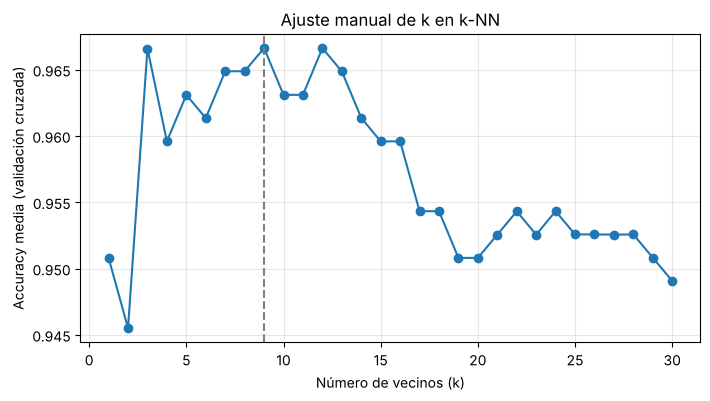

In [17]:
X, y = load_breast_cancer(return_X_y=True)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

valores_k = range(1, 31)
medias = []
for k in valores_k:
    modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    medias.append(cross_val_score(modelo, X, y, cv=skf).mean())

mejor_k = valores_k[int(np.argmax(medias))]
print(f"Mejor k = {mejor_k} con accuracy media = {max(medias):.3f}")

plt.figure(figsize=(8, 4))
plt.plot(valores_k, medias, marker="o")
plt.axvline(mejor_k, color="gray", linestyle="--")
plt.xlabel("Número de vecinos (k)")
plt.ylabel("Accuracy media (validación cruzada)")
plt.title("Ajuste manual de k en k-NN")
plt.grid(alpha=0.3)
plt.show()

Esto funciona con **un** hiperparámetro, pero ¿y si queremos probar varios a la vez (por ejemplo `k`, `weights` y `p`)? Necesitaríamos bucles anidados. Para eso existen `GridSearchCV` y `RandomizedSearchCV`.

## 8. `GridSearchCV`: búsqueda exhaustiva en una rejilla

`GridSearchCV` prueba **todas las combinaciones** de los valores que le indiquemos y evalúa cada una con validación cruzada.

Pasos:
1. Definir el modelo.
2. Definir la rejilla (`param_grid`): un diccionario `{nombre_hiperparámetro: [valores a probar]}`.
3. Crear `GridSearchCV(modelo, param_grid, cv=..., scoring=...)` y llamar a `fit`.
4. Consultar `best_params_`, `best_score_` y `best_estimator_`.

**Buena práctica:** separar antes un conjunto de test que **no se usa en la búsqueda**, para comprobar al final el modelo elegido con datos totalmente nuevos.

### Ejemplo 8.1 — Árbol de decisión

In [18]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

param_grid = {
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_split": [2, 5, 10, 20],
    "criterion": ["gini", "entropy"],
}
# Combinaciones: 6 × 4 × 2 = 48  → con 5 folds = 240 entrenamientos

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
)
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
print(f"Accuracy media en validación cruzada: {grid.best_score_:.3f}")
print(f"Accuracy en el test reservado:        {grid.score(X_test, y_test):.3f}")

Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_split': 10}
Accuracy media en validación cruzada: 0.936
Accuracy en el test reservado:        0.930


Tras la búsqueda, `grid` **reentrena automáticamente** el mejor modelo con todos los datos de entrenamiento (`refit=True` por defecto). Por eso podemos usar directamente `grid.predict(...)` o `grid.score(...)`.

### Ver todos los resultados con `cv_results_`

In [19]:
resultados = pd.DataFrame(grid.cv_results_)
columnas = ["param_max_depth", "param_min_samples_split", "param_criterion",
            "mean_test_score", "std_test_score", "rank_test_score"]
resultados[columnas].sort_values("rank_test_score").head(10)

,param_max_depth,param_min_samples_split,param_criterion,mean_test_score,std_test_score,rank_test_score
34,4,10,entropy,0.936264,0.021308,1
28,3,2,entropy,0.934066,0.024076,2
30,3,10,entropy,0.934066,0.024076,2
29,3,5,entropy,0.934066,0.024076,2
32,4,2,entropy,0.934066,0.013900,2
33,4,5,entropy,0.934066,0.013900,2
2,2,10,gini,0.931868,0.018906,7
0,2,2,gini,0.931868,0.018906,7
3,2,20,gini,0.931868,0.018906,7
1,2,5,gini,0.931868,0.018906,7


### Ejemplo 8.2 — k-NN con escalado (rejilla dentro de un pipeline)

Como vimos en la sección 6, cuando el modelo está dentro de un pipeline, el nombre del hiperparámetro se escribe como `nombrepaso__hiperparametro` (con **dos** guiones bajos). Gracias al pipeline, el escalado se repite correctamente dentro de cada fold de la búsqueda.

In [20]:
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
print("Nombres de los pasos:", list(pipe.named_steps))

param_grid = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11, 15],
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2],      # 1 = Manhattan, 2 = Euclídea
}

grid_knn = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy")
grid_knn.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid_knn.best_params_)
print(f"Accuracy CV:   {grid_knn.best_score_:.3f}")
print(f"Accuracy test: {grid_knn.score(X_test, y_test):.3f}")

Nombres de los pasos: ['standardscaler', 'kneighborsclassifier']


Mejores hiperparámetros: {'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'uniform'}
Accuracy CV:   0.971
Accuracy test: 0.974


### Ejemplo 8.3 — Buscar el grado polinómico de una regresión lineal

Es el ejemplo 6.5, pero ahora `GridSearchCV` hace el bucle por nosotros.

In [21]:
X_d, y_d = load_diabetes(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_d, y_d, test_size=0.2, random_state=42)

pipe = make_pipeline(PolynomialFeatures(), StandardScaler(), LinearRegression())
param_grid = {"polynomialfeatures__degree": [1, 2, 3]}

grid_poly = GridSearchCV(pipe, param_grid, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
grid_poly.fit(Xd_train, yd_train)

for grado, r2 in zip(param_grid["polynomialfeatures__degree"], grid_poly.cv_results_["mean_test_score"]):
    print(f"Grado {grado}: R² medio en CV = {r2:.3f}")
print("Mejor:", grid_poly.best_params_, f"→ R² en test = {grid_poly.score(Xd_test, yd_test):.3f}")

Grado 1: R² medio en CV = 0.480
Grado 2: R² medio en CV = 0.339
Grado 3: R² medio en CV = -476.019
Mejor: {'polynomialfeatures__degree': 1} → R² en test = 0.453


### Ejemplo 8.4 — Buscar también el paso de preprocesamiento

En la rejilla podemos **sustituir un paso entero** por otro objeto. Con `"passthrough"` el paso no hace nada. Así comprobamos si a k-NN le conviene escalar y con qué escalador:
- `StandardScaler`: deja cada variable con media 0 y desviación 1.
- `MinMaxScaler`: lleva cada variable al rango [0, 1].

In [22]:
from sklearn.preprocessing import MinMaxScaler

pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
param_grid = {
    "standardscaler": [StandardScaler(), MinMaxScaler(), "passthrough"],   # el paso entero
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11],
}

grid_esc = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42))
grid_esc.fit(X_train, y_train)

res = pd.DataFrame(grid_esc.cv_results_)
res["escalado"] = res["param_standardscaler"].astype(str)
print(res.pivot_table(index="escalado", columns="param_kneighborsclassifier__n_neighbors",
                      values="mean_test_score").round(3))
print("\nMejor combinación:", grid_esc.best_params_)

param_kneighborsclassifier__n_neighbors     3      5      7      9      11
escalado                                                                  
MinMaxScaler()                           0.967  0.971  0.974  0.974  0.971
StandardScaler()                         0.963  0.963  0.963  0.965  0.963
passthrough                              0.932  0.941  0.936  0.934  0.934

Mejor combinación: {'kneighborsclassifier__n_neighbors': 7, 'standardscaler': MinMaxScaler()}


Sin escalar (`passthrough`), k-NN funciona claramente peor. Las variables de este dataset tienen escalas muy distintas, y las de valores grandes dominan el cálculo de la distancia.

Fíjate en que el paso se sigue llamando `standardscaler` aunque lo sustituyamos por otro: el nombre se asigna al crear el pipeline. Con `Pipeline([("escalado", ...), ...])` quedaría más claro.

**Ventaja:** encuentra la mejor combinación **dentro de la rejilla**.
**Inconveniente:** el número de combinaciones crece muy rápido. Con 5 hiperparámetros de 10 valores cada uno serían 100 000 combinaciones (¡× 5 folds!).

## 9. `RandomizedSearchCV`: búsqueda aleatoria

En lugar de probar todas las combinaciones, `RandomizedSearchCV` prueba **un número fijo de combinaciones elegidas al azar** (`n_iter`).

- Podemos darle listas de valores o **distribuciones** (por ejemplo, cualquier entero entre 1 y 50).
- Controlamos el tiempo de cálculo con `n_iter`.
- En la práctica suele encontrar soluciones casi tan buenas como `GridSearchCV` en mucho menos tiempo.

Distribuciones útiles de `scipy.stats`:
- `randint(a, b)`: enteros entre `a` y `b-1` (ideal para `max_depth`, `n_neighbors`…).
- `loguniform(a, b)`: valores repartidos en escala logarítmica (ideal para `C`, que puede ir de 0.001 a 1000).

### Ejemplo 9.1 — Regresión logística: buscar `C`

In [23]:
from scipy.stats import loguniform, randint

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

param_dist = {"logisticregression__C": loguniform(1e-3, 1e3)}

rnd_log = RandomizedSearchCV(pipe, param_dist, n_iter=20, cv=5,
                             scoring="accuracy", random_state=42)
rnd_log.fit(X_train, y_train)

print(f"Mejor C: {rnd_log.best_params_['logisticregression__C']:.4f}")
print(f"Accuracy CV:   {rnd_log.best_score_:.3f}")
print(f"Accuracy test: {rnd_log.score(X_test, y_test):.3f}")

Mejor C: 0.3905
Accuracy CV:   0.980
Accuracy test: 0.982


Veamos qué valores de `C` ha probado y cómo le ha ido a cada uno:

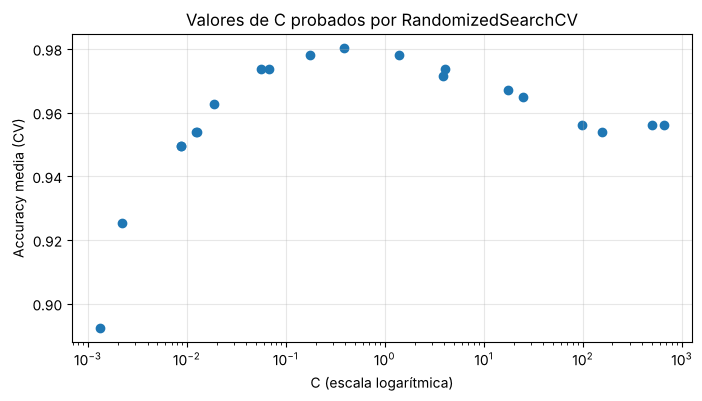

In [24]:
res = pd.DataFrame(rnd_log.cv_results_)
c_probados = res["param_logisticregression__C"].astype(float)

plt.figure(figsize=(8, 4))
plt.scatter(c_probados, res["mean_test_score"])
plt.xscale("log")
plt.xlabel("C (escala logarítmica)")
plt.ylabel("Accuracy media (CV)")
plt.title("Valores de C probados por RandomizedSearchCV")
plt.grid(alpha=0.3)
plt.show()

### Ejemplo 9.2 — Árbol de decisión con varios hiperparámetros

In [25]:
param_dist = {
    "max_depth": randint(1, 20),
    "min_samples_split": randint(2, 50),
    "min_samples_leaf": randint(1, 20),
    "criterion": ["gini", "entropy"],
}

rnd_arbol = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_dist,
    n_iter=30,                         # solo 30 combinaciones al azar
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
    random_state=42,
)
rnd_arbol.fit(X_train, y_train)

print("Mejores hiperparámetros:", rnd_arbol.best_params_)
print(f"Accuracy CV:   {rnd_arbol.best_score_:.3f}")
print(f"Accuracy test: {rnd_arbol.score(X_test, y_test):.3f}")

Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 14, 'min_samples_leaf': 18, 'min_samples_split': 10}
Accuracy CV:   0.934
Accuracy test: 0.904


Si hubiéramos usado una rejilla con todos esos valores serían 19 × 48 × 19 × 2 = **34 656 combinaciones**. Aquí solo hemos probado 30.

## 10. Comparación: `GridSearchCV` vs. `RandomizedSearchCV`

Buscamos `n_neighbors` en k-NN con ambos métodos y medimos tiempo y resultado.

In [26]:
import time

pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())

# Grid: prueba todos los k de 1 a 50 con las dos opciones de weights → 100 combinaciones
grid = GridSearchCV(pipe, {
    "kneighborsclassifier__n_neighbors": list(range(1, 51)),
    "kneighborsclassifier__weights": ["uniform", "distance"],
}, cv=5)

# Random: solo 15 combinaciones al azar del mismo espacio
rnd = RandomizedSearchCV(pipe, {
    "kneighborsclassifier__n_neighbors": randint(1, 51),
    "kneighborsclassifier__weights": ["uniform", "distance"],
}, n_iter=15, cv=5, random_state=42)

for nombre, buscador in [("GridSearchCV", grid), ("RandomizedSearchCV", rnd)]:
    inicio = time.time()
    buscador.fit(X_train, y_train)
    print(f"{nombre:20s} | combinaciones: {len(buscador.cv_results_['params']):3d} | "
          f"tiempo: {time.time() - inicio:5.2f} s | "
          f"accuracy CV: {buscador.best_score_:.3f} | mejores: {buscador.best_params_}")

GridSearchCV         | combinaciones: 100 | tiempo:  2.15 s | accuracy CV: 0.974 | mejores: {'kneighborsclassifier__n_neighbors': 8, 'kneighborsclassifier__weights': 'distance'}


RandomizedSearchCV   | combinaciones:  15 | tiempo:  0.31 s | accuracy CV: 0.967 | mejores: {'kneighborsclassifier__n_neighbors': 12, 'kneighborsclassifier__weights': 'distance'}


| | `GridSearchCV` | `RandomizedSearchCV` |
|---|---|---|
| Qué prueba | Todas las combinaciones | `n_iter` combinaciones al azar |
| Coste | Crece muy rápido con el número de hiperparámetros | Lo controlamos con `n_iter` |
| Garantía | Encuentra el mejor **de la rejilla** | Puede no dar con el mejor exacto, pero suele quedarse muy cerca |
| Valores continuos (`C`) | Hay que elegir unos pocos valores | Puede muestrear cualquier valor de una distribución |
| Cuándo usarlo | Pocos hiperparámetros y pocos valores | Muchos hiperparámetros o rangos amplios |

**Estrategia práctica habitual:** primero `RandomizedSearchCV` con rangos amplios para localizar la zona buena, y después `GridSearchCV` con una rejilla fina alrededor de esa zona.

## 11. Resumen y errores frecuentes

**Flujo de trabajo recomendado**
1. Separar un conjunto de **test** (`train_test_split`, con `stratify=y` si es clasificación) y no tocarlo hasta el final.
2. Elegir la estrategia de validación: `KFold` (regresión) o `StratifiedKFold` (clasificación).
3. Buscar hiperparámetros con `GridSearchCV` o `RandomizedSearchCV` **solo sobre el entrenamiento**.
4. Evaluar el mejor modelo **una única vez** en el test.

**Errores frecuentes**
- Elegir hiperparámetros mirando la puntuación en el **test**: el test deja de ser "datos nuevos" y el resultado sale optimista.
- **Preprocesar todos los datos antes** de la validación cruzada (escalar, imputar, seleccionar variables): la información de los folds de prueba se cuela en el entrenamiento. Mete el preprocesamiento en un pipeline.
- Escalar el test con `fit_transform` en lugar de `transform` (el pipeline lo evita).
- Usar `KFold` sin `shuffle=True` con datos ordenados.
- Olvidar el doble guion bajo (`paso__hiperparametro`) al buscar dentro de un pipeline.
- Rejillas enormes en `GridSearchCV`: calcula antes cuántas combinaciones son.

## 12. Ejercicios propuestos

1. **cross_val_score**: evalúa una `LinearRegression` y un `DecisionTreeRegressor(max_depth=4)` sobre `load_diabetes` con `cv=10`. ¿Cuál tiene mejor R² medio? ¿Cuál es más estable?
2. **KFold**: repite el ejemplo 4.3 con `n_splits=5` y `n_splits=10`. ¿Qué ocurre sin barajar?
3. **StratifiedKFold**: con `load_iris`, imprime la proporción de cada clase en los folds de prueba usando `KFold(shuffle=False)` y `StratifiedKFold`.
4. **Pipelines**: crea un pipeline `SimpleImputer → StandardScaler → LogisticRegression` para `load_breast_cancer` con un 5 % de valores `NaN` simulados. Evalúalo con `StratifiedKFold`. Después prueba `strategy="median"` en el imputador con `set_params`.
5. **GridSearchCV**: busca el mejor `max_depth` (1 a 10) y `min_samples_leaf` (1, 5, 10) para un `DecisionTreeRegressor` en `load_diabetes` usando `scoring="neg_mean_absolute_error"`.
6. **GridSearchCV + pipeline**: repite el ejemplo 8.4 con un árbol de decisión en lugar de k-NN. ¿Influye el escalado en un árbol? ¿Por qué?
7. **RandomizedSearchCV**: para k-NN en `load_breast_cancer`, prueba `n_iter` = 5, 10 y 30. ¿Cómo cambian el resultado y el tiempo?

In [27]:
# Espacio para los ejercicios